# MMIP - Week 5

| Quiz | 主題 | 章節 |
|---|---|---|
| 1 | 影像檢索：自備資料集、訓練、推論，並比較 **CNN (ResNet-50)** 與 **ViT (ViT-B/16)** | 1.1 ~ 1.6 |
| 2 | 多模態深度學習：影像 + 文字 Backbone 萃取特徵 → 融合 → 分類，並更換 Backbone 比較 | 2.1 ~ 2.7 |
| 3 | CLIP：以 CLIP 作為 Image Encoder + 文字 Decoder (GPT-2) 建立 Image Captioning，與 Week 4 比較 BLEU / BERTScore | 3.1 ~ 3.7 |

**環境：** Python 3.11、CUDA 12.6 版 PyTorch、NVIDIA RTX 3060。資料集皆以 `kagglehub` 下載。

> 若想先快速驗證程式能跑通，將下方設定的 `QUICK = True`，跑完再改回 `False` 做正式實驗。

## 0. 環境與共用設定

In [2]:
import os, sys, time, random, re, json, copy, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

warnings.filterwarnings("ignore")

# ---------- 基本設定 ----------
QUICK = False          # True：小資料 + 少 epoch，只用來檢查程式是否能跑
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"

ROOT = Path(".").resolve()
DATA_DIR = ROOT / "data"        # kagglehub 快取、特徵快取
OUT_DIR = ROOT / "outputs"      # 結果表格、圖
DATA_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
os.environ.setdefault("KAGGLEHUB_CACHE", str(DATA_DIR / "kagglehub"))

# Windows + Jupyter 使用多個 DataLoader worker 容易卡住，所以 Windows 設為 0
NUM_WORKERS = 0 if os.name == "nt" else 4

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("torch:", torch.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only)) / 1e6

def sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(IMNET_MEAN, IMNET_STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize(IMNET_MEAN, IMNET_STD)])

torch: 2.14.1+cu126 | device: cuda
GPU: NVIDIA GeForce RTX 3060


---
# Quiz 1：影像檢索（Image Retrieval）

**做法：** 以 Backbone 取出影像特徵，經投影層得到 256 維、L2 正規化的 embedding，並以 **cosine classifier（以類別為 proxy 的度量學習）** 訓練，使同類影像在 embedding 空間中靠近。檢索時以 cosine 相似度排序，同類別視為相關結果。

- Backbone A：**CNN** — ResNet-50（ImageNet 預訓練）
- Backbone B：**Vision Transformer** — ViT-B/16（ImageNet 預訓練）
- 評估指標：Recall@1/5/10、Precision@K、mAP；另外附上「未微調（ImageNet 預訓練特徵）」作為對照。

## 1.1 準備影像檢索資料集（Animals-10）

資料位置: D:\Projects\MMIP\week5\data\kagglehub\datasets\alessiocorrado99\animals10\versions\2\raw-img
總張數 4000 | 訓練 2800 | 檢索評估(Query/Gallery) 1200 | 類別數 10
{'dog': 400, 'horse': 400, 'elephant': 400, 'butterfly': 400, 'chicken': 400, 'cat': 400, 'cow': 400, 'sheep': 400, 'spider': 400, 'squirrel': 400}


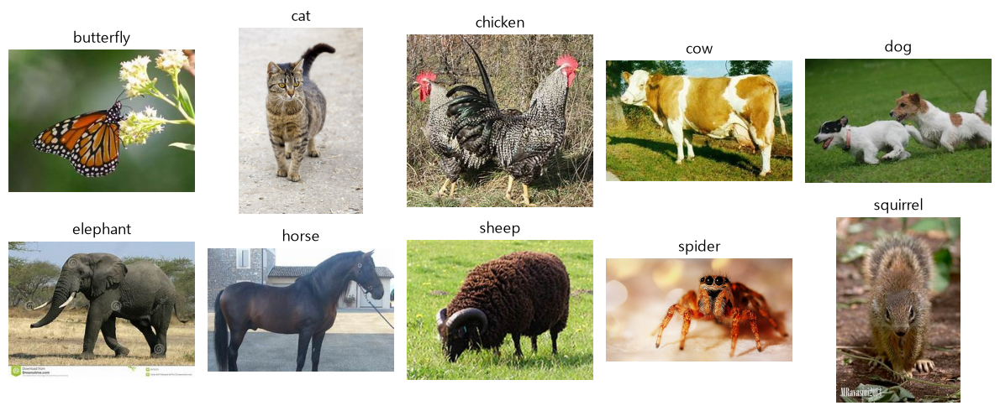

In [3]:
import kagglehub
from sklearn.model_selection import train_test_split

animals_root = Path(kagglehub.dataset_download("alessiocorrado99/animals10"))
raw_dir = next(p for p in animals_root.rglob("raw-img") if p.is_dir())
print("資料位置:", raw_dir)

IT2EN = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly",
         "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep",
         "ragno": "spider", "scoiattolo": "squirrel"}
IMG_EXT = {".jpg", ".jpeg", ".png"}
PER_CLASS_RET = 40 if QUICK else 400     # 每類取樣張數
EPOCHS_RET = 1 if QUICK else 5

rng = random.Random(SEED)
records = []
for cls_dir in sorted(p for p in raw_dir.iterdir() if p.is_dir()):
    files = sorted(f for f in cls_dir.iterdir() if f.suffix.lower() in IMG_EXT)
    rng.shuffle(files)
    for f in files[:PER_CLASS_RET]:
        records.append((str(f), IT2EN.get(cls_dir.name, cls_dir.name)))

df_ret = pd.DataFrame(records, columns=["path", "label"])
classes = sorted(df_ret.label.unique())
c2i = {c: i for i, c in enumerate(classes)}
df_ret["y"] = df_ret.label.map(c2i)

# 70% 訓練；30% 作為檢索評估集（同時是 Query 與 Gallery，檢索時排除自己）
tr_df, te_df = train_test_split(df_ret, test_size=0.3, stratify=df_ret.y, random_state=SEED)
tr_df = tr_df.reset_index(drop=True); te_df = te_df.reset_index(drop=True)
print(f"總張數 {len(df_ret)} | 訓練 {len(tr_df)} | 檢索評估(Query/Gallery) {len(te_df)} | 類別數 {len(classes)}")
print(df_ret.label.value_counts().to_dict())

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, c in zip(axes.ravel(), classes):
    ax.imshow(Image.open(df_ret[df_ret.label == c].path.iloc[0]).convert("RGB")); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

## 1.2 建立檢索模型（Backbone + 投影層 + Cosine Classifier）

In [4]:
class ImgDS(Dataset):
    def __init__(self, df, tf): self.paths, self.ys, self.tf = df.path.tolist(), df.y.tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.ys[i]

def make_loader(df, tf, shuffle, bs=32):
    return DataLoader(ImgDS(df, tf), batch_size=bs, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE == "cuda"), drop_last=shuffle)

class RetrievalNet(nn.Module):
    """Backbone -> Linear+BN (256 維) -> L2 normalize；訓練時以 cosine classifier 做監督"""
    def __init__(self, arch, emb_dim=256, num_classes=10, scale=30.0):
        super().__init__()
        if arch == "resnet50":
            m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
            feat = m.fc.in_features; m.fc = nn.Identity()
        elif arch == "vit_b_16":
            m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
            feat = m.heads.head.in_features; m.heads = nn.Identity()
        else:
            raise ValueError(arch)
        self.backbone = m
        self.proj = nn.Sequential(nn.Linear(feat, emb_dim), nn.BatchNorm1d(emb_dim))
        self.classifier = nn.Parameter(torch.randn(num_classes, emb_dim) * 0.01)
        self.scale = scale

    def embed(self, x):
        return F.normalize(self.proj(self.backbone(x)).float(), dim=-1)

    def forward(self, x):
        e = self.embed(x)
        return e, self.scale * e @ F.normalize(self.classifier, dim=-1).T

for a in ["resnet50", "vit_b_16"]:
    print(a, f"參數量 {count_params(RetrievalNet(a)):.2f} M")

resnet50 參數量 24.04 M
vit_b_16 參數量 86.00 M


## 1.3 檢索評估函式與訓練流程

In [5]:
@torch.no_grad()
def extract_embeddings(model, loader, raw_backbone=False):
    """raw_backbone=True：直接使用 Backbone 的預訓練特徵（未微調對照組）"""
    model.eval(); embs, ys = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            e = F.normalize(model.backbone(x).float(), dim=-1) if raw_backbone else model.embed(x)
        embs.append(e.float().cpu()); ys.append(y)
    return torch.cat(embs), torch.cat(ys)

@torch.no_grad()
def retrieval_metrics(emb, labels, ks=(1, 5, 10)):
    """Query = Gallery = 評估集，排除自己；相關 = 同類別"""
    emb, labels = emb.to(DEVICE), labels.to(DEVICE)
    sim = emb @ emb.T
    sim.fill_diagonal_(-float("inf"))
    order = sim.argsort(dim=1, descending=True)[:, :-1]          # 最後一欄是自己
    rel = (labels[order] == labels[:, None]).float()
    out = {}
    for k in ks:
        out[f"Recall@{k}"] = rel[:, :k].max(1).values.mean().item()
        out[f"P@{k}"] = rel[:, :k].mean().item()
    prec = rel.cumsum(1) / torch.arange(1, rel.shape[1] + 1, device=rel.device)
    out["mAP"] = ((prec * rel).sum(1) / rel.sum(1).clamp(min=1)).mean().item()
    return out

LR_BACKBONE = {"resnet50": 1e-4, "vit_b_16": 3e-5}

def run_retrieval_experiment(arch, epochs=EPOCHS_RET):
    set_seed()
    model = RetrievalNet(arch, num_classes=len(classes)).to(DEVICE)
    tr_loader = make_loader(tr_df, train_tf, True); te_loader = make_loader(te_df, eval_tf, False, bs=64)

    e0, y0 = extract_embeddings(model, te_loader, raw_backbone=True)       # 未微調對照
    res_pre = retrieval_metrics(e0, y0)

    opt = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": LR_BACKBONE[arch]},
        {"params": list(model.proj.parameters()) + [model.classifier], "lr": 1e-3}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(tr_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    hist = []; sync(); t0 = time.time()
    for ep in range(epochs):
        model.train(); tot, n, correct = 0.0, 0, 0
        for x, y in tqdm(tr_loader, desc=f"{arch} ep{ep+1}/{epochs}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                _, logits = model(x)
            loss = F.cross_entropy(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y); correct += (logits.argmax(1) == y).sum().item()
        hist.append({"epoch": ep + 1, "loss": tot / n, "train_acc": correct / n})
        print(f"[{arch}] epoch {ep+1}: loss {tot/n:.4f} | train acc {correct/n:.4f}")
    sync(); train_time = time.time() - t0

    sync(); t0 = time.time()
    e1, y1 = extract_embeddings(model, te_loader); sync(); infer_time = time.time() - t0
    res = retrieval_metrics(e1, y1)
    return dict(arch=arch, params=count_params(model), train_time=train_time, infer_time=infer_time,
                pre=res_pre, post=res, hist=pd.DataFrame(hist), emb=e1, y=y1)

## 1.4 訓練 CNN 與 ViT 檢索模型

In [6]:
RET = {}
RET["CNN (ResNet-50)"] = run_retrieval_experiment("resnet50")
torch.cuda.empty_cache()
RET["ViT (ViT-B/16)"] = run_retrieval_experiment("vit_b_16")
torch.cuda.empty_cache()

resnet50 ep1/5:   0%|          | 0/87 [00:00<?, ?it/s]

[resnet50] epoch 1: loss 0.5553 | train acc 0.8886


resnet50 ep2/5:   0%|          | 0/87 [00:00<?, ?it/s]

[resnet50] epoch 2: loss 0.1564 | train acc 0.9648


resnet50 ep3/5:   0%|          | 0/87 [00:00<?, ?it/s]

...

[vit_b_16] epoch 3: loss 0.0345 | train acc 0.9910


vit_b_16 ep4/5:   0%|          | 0/87 [00:00<?, ?it/s]

[vit_b_16] epoch 4: loss 0.0140 | train acc 0.9968


vit_b_16 ep5/5:   0%|          | 0/87 [00:00<?, ?it/s]

[vit_b_16] epoch 5: loss 0.0068 | train acc 0.9975


## 1.5 檢索推論：展示檢索結果（綠框＝同類別，紅框＝不同類別）

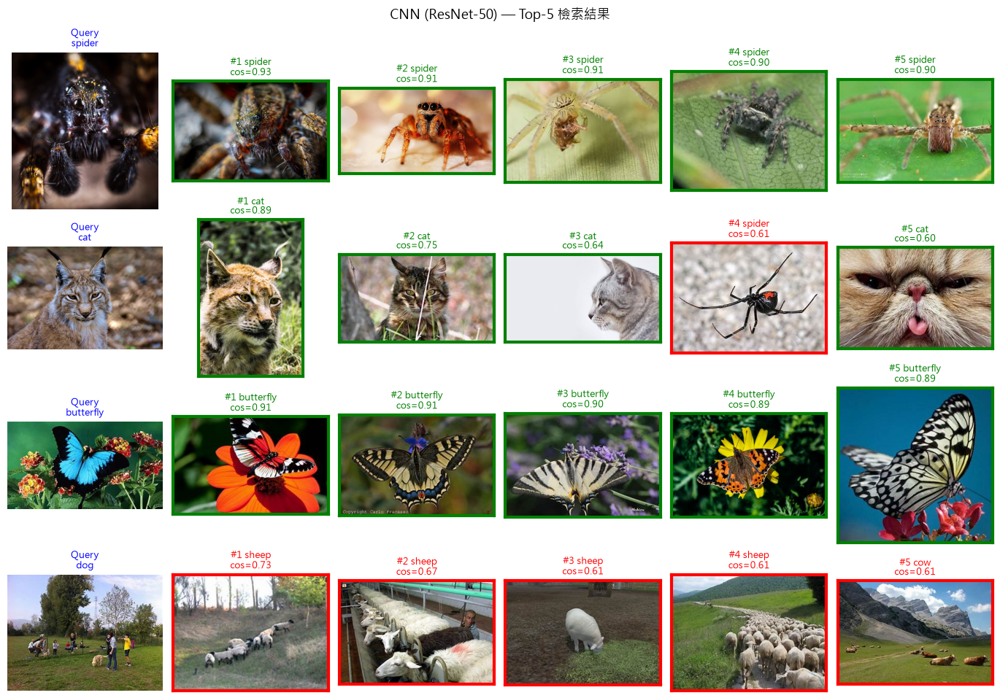

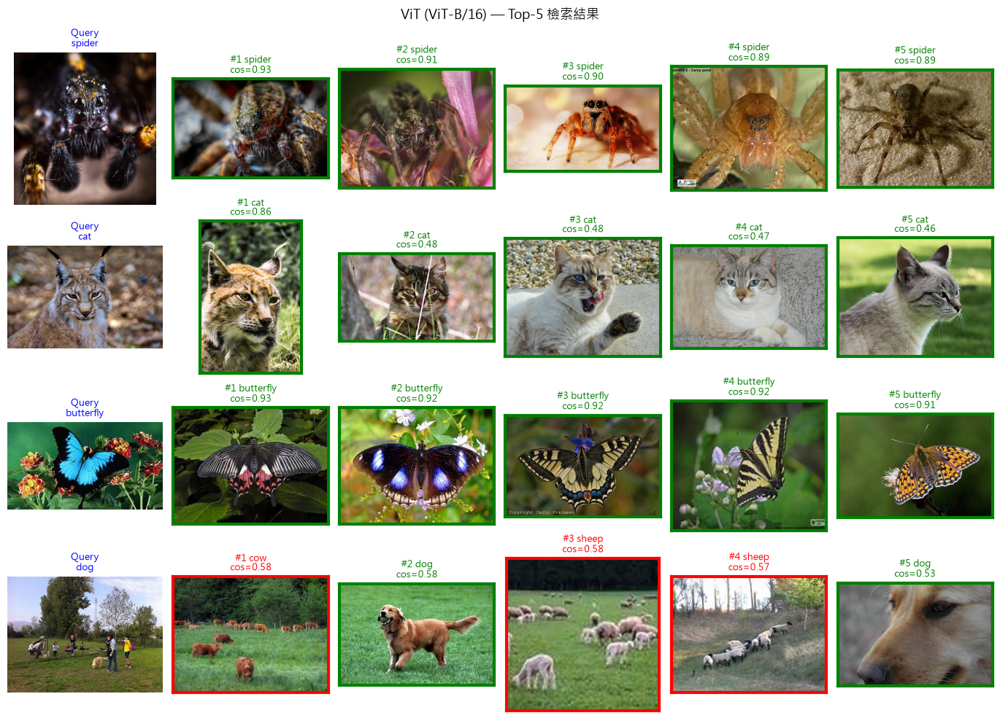

In [7]:
def show_retrieval(emb, df, title, n_query=4, topk=5, seed=0):
    paths, labels = df.path.tolist(), df.y.values
    sim = emb @ emb.T; sim.fill_diagonal_(-float("inf"))
    top = sim.topk(topk, dim=1).indices.numpy()
    qs = np.random.RandomState(seed).choice(len(paths), n_query, replace=False)
    fig, axes = plt.subplots(n_query, topk + 1, figsize=(2.3 * (topk + 1), 2.5 * n_query))
    for r, q in enumerate(qs):
        axes[r, 0].imshow(Image.open(paths[q]).convert("RGB"))
        axes[r, 0].set_title("Query\n" + classes[labels[q]], fontsize=9, color="blue")
        for c, j in enumerate(top[q]):
            ax = axes[r, c + 1]; ax.imshow(Image.open(paths[j]).convert("RGB"))
            ok = labels[j] == labels[q]
            ax.set_title(f"#{c+1} {classes[labels[j]]}\ncos={sim[q, j]:.2f}", fontsize=9, color="green" if ok else "red")
            for s in ax.spines.values(): s.set_edgecolor("green" if ok else "red"); s.set_linewidth(3)
            ax.set_xticks([]); ax.set_yticks([])
        axes[r, 0].axis("off")
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()

for name, r in RET.items():
    show_retrieval(r["emb"], te_df, f"{name} — Top-5 檢索結果")

## 1.6 CNN vs ViT 檢索表現比較

,Backbone,微調,Recall@1,P@1,Recall@5,P@5,Recall@10,P@10,mAP,參數量(M),訓練時間(s),推論時間(s)
0,CNN (ResNet-50),否 (ImageNet 特徵),0.9650,0.9650,0.9892,0.9518,0.9917,0.9437,0.8257,NaN,NaN,NaN
1,CNN (ResNet-50),是,0.9650,0.9650,0.9825,0.9642,0.9858,0.9636,0.9423,24.0356,69.1807,3.3342
2,ViT (ViT-B/16),否 (ImageNet 特徵),0.9600,0.9600,0.9825,0.9532,0.9850,0.9452,0.8274,NaN,NaN,NaN
3,ViT (ViT-B/16),是,0.9675,0.9675,0.9850,0.9675,0.9875,0.9665,0.9552,85.9986,140.4511,4.8630


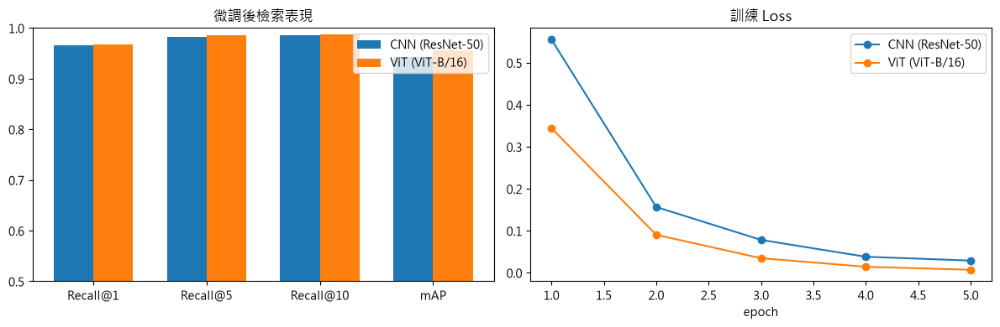

Recall@1: CNN 0.9650 vs ViT 0.9675  → 較高者：ViT
Recall@5: CNN 0.9825 vs ViT 0.9850  → 較高者：ViT
mAP: CNN 0.9423 vs ViT 0.9552  → 較高者：ViT
參數量: CNN 24.0M vs ViT 86.0M | 訓練時間: 69.2s vs 140.5s | 推論時間: 3.33s vs 4.86s


In [8]:
rows = []
for name, r in RET.items():
    rows.append({"Backbone": name, "微調": "否 (ImageNet 特徵)", **{k: v for k, v in r["pre"].items()}})
    rows.append({"Backbone": name, "微調": "是", **{k: v for k, v in r["post"].items()},
                 "參數量(M)": r["params"], "訓練時間(s)": r["train_time"], "推論時間(s)": r["infer_time"]})
ret_table = pd.DataFrame(rows)
ret_table.to_csv(OUT_DIR / "quiz1_retrieval_results.csv", index=False, encoding="utf-8-sig")
display(ret_table.round(4))

# 圖：微調後 Recall@K 與 mAP
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics = ["Recall@1", "Recall@5", "Recall@10", "mAP"]
w = 0.35
for i, (name, r) in enumerate(RET.items()):
    axes[0].bar(np.arange(4) + i * w, [r["post"][m] for m in metrics], w, label=name)
axes[0].set_xticks(np.arange(4) + w / 2); axes[0].set_xticklabels(metrics); axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("微調後檢索表現"); axes[0].legend()
for name, r in RET.items():
    axes[1].plot(r["hist"].epoch, r["hist"].loss, marker="o", label=name)
axes[1].set_title("訓練 Loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "quiz1_compare.png", dpi=150); plt.show()

# 自動摘要（數字以實際執行結果為準）
a, b = RET["CNN (ResNet-50)"], RET["ViT (ViT-B/16)"]
for m in ["Recall@1", "Recall@5", "mAP"]:
    print(f"{m}: CNN {a['post'][m]:.4f} vs ViT {b['post'][m]:.4f}  → 較高者：{'CNN' if a['post'][m] > b['post'][m] else 'ViT'}")
print(f"參數量: CNN {a['params']:.1f}M vs ViT {b['params']:.1f}M | 訓練時間: {a['train_time']:.1f}s vs {b['train_time']:.1f}s | 推論時間: {a['infer_time']:.2f}s vs {b['infer_time']:.2f}s")

### Quiz 1 結果分析

- 微調後 ViT-B/16 的 mAP 最高（0.9552），略高於 ResNet-50（0.9423）；兩者 Recall@1 皆約 0.97。
- 微調使兩種模型的 mAP 明顯提升：ResNet-50 由 0.8257 提升至 0.9423，ViT-B/16 由 0.8274 提升至 0.9552。
- ResNet-50 訓練與推論較快（69.2 秒、3.33 秒）；ViT-B/16 檢索表現稍好，但耗時較長（140.5 秒、4.86 秒）。
- 本實驗每類取樣 400 張，且以類別相同定義相關影像；結果仍受資料量與單一隨機種子限制。

---
# Quiz 2：多模態深度學習（影像 + 文字分類）

**資料集：** 使用 Flickr8k（影像 + 每張 5 句英文描述），自行建立「場景類別」標籤：

`dog`（狗）、`water`（水邊活動）、`ball_sport`（球類運動）、`climbing`（攀爬 / 山 / 雪）、`street`（街道 / 城市）

- 以關鍵字規則統計 5 句描述：某類別至少在 **2 句**描述中命中才給標籤，並對各類別取樣平衡。
-  **標籤洩漏說明：** 標籤由文字關鍵字產生，因此文字模態天然具有強訊號。為了讓比較有意義，除了「融合」之外，本 Notebook 另外跑 **image-only / text-only 消融實驗**，並在分析時說明這個限制。

**模型：** 凍結的影像 Backbone 與文字 Backbone 先萃取特徵 → 各自投影 → concat 融合 → MLP 分類頭。

| 影像 Backbone | 文字 Backbone |
|---|---|
| ResNet-50 (2048 維)、ViT-B/16 (768 維) | DistilBERT (768 維)、MiniLM-L6 (384 維) |

共 2 × 2 = 4 種 Backbone 組合（基準組合為 ResNet-50 + DistilBERT，其餘為更換 Backbone 的組合）。

## 2.1 準備多模態資料集（Flickr8k → 場景分類）

Flickr8k: 8091 張影像, 40455 句描述 | 影像資料夾: D:\Projects\MMIP\week5\data\kagglehub\datasets\adityajn105\flickr8k\versions\1\Images
{'climbing': 500, 'dog': 500, 'street': 500, 'water': 500, 'ball_sport': 498} | 影像總數: 2498
影像: 訓練 1748 / 驗證 375 / 測試 375 ；配對: 8740 / 1875 / 1875


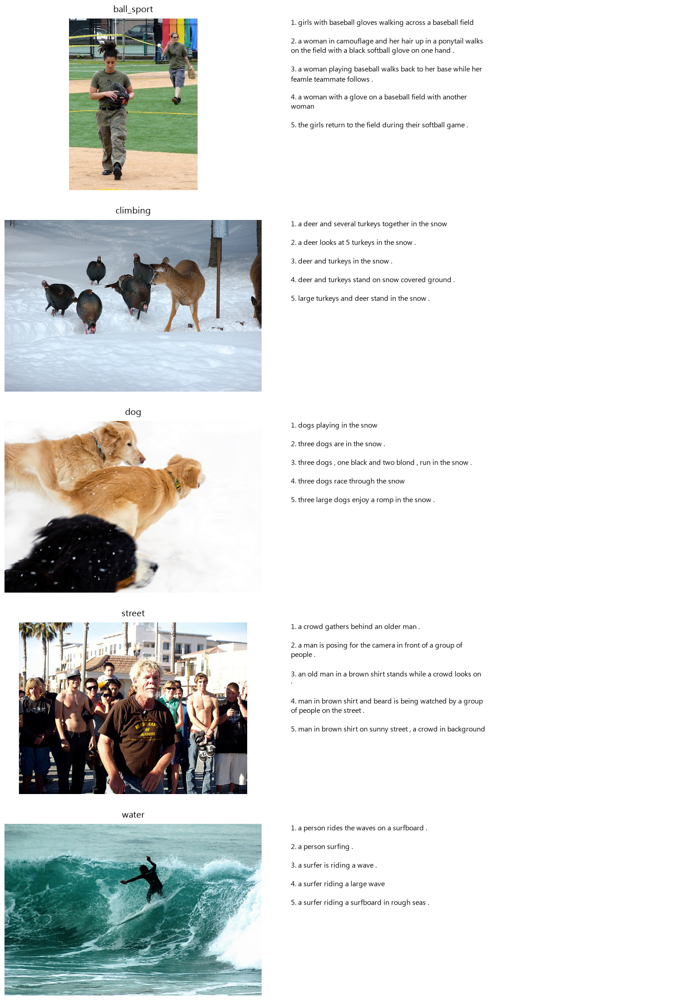

In [9]:
flickr_root = Path(kagglehub.dataset_download("adityajn105/flickr8k"))
cap_file = next(flickr_root.rglob("captions.txt"))
IMG_DIR = next(flickr_root.rglob("*.jpg")).parent
cap_df = pd.read_csv(cap_file); cap_df.columns = ["image", "caption"]
cap_df["caption"] = cap_df.caption.astype(str).str.lower().str.strip()
print("Flickr8k:", cap_df.image.nunique(), "張影像,", len(cap_df), "句描述 | 影像資料夾:", IMG_DIR)

CAT_PATTERNS = {
    "dog":        r"\b(dogs?|pupp(?:y|ies))\b",
    "water":      r"\b(water|swim\w*|beach|ocean|sea|pool|surf\w*|waves?|lake|river|boats?)\b",
    "ball_sport": r"\b(ball|soccer|football|basketball|baseball|tennis|volleyball|rugby|goal)\b",
    "climbing":   r"\b(climb\w*|rocks?|mountains?|cliff|hik\w*|snow\w*|ski\w*)\b",
    "street":     r"\b(streets?|city|buildings?|sidewalk|road|crowd|market)\b",
}
def assign_label(caps):
    scores = {c: sum(bool(re.search(p, t)) for t in caps) for c, p in CAT_PATTERNS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] >= 2 else None

grp = cap_df.groupby("image").caption.apply(list)
lab = {img: assign_label(caps) for img, caps in grp.items()}
mm = pd.DataFrame({"image": list(lab), "label": list(lab.values())}).dropna()

PER_CLASS_MM = 60 if QUICK else 500
sampled = [
    group.sample(n=min(len(group), PER_CLASS_MM), random_state=SEED)
    for _, group in mm.groupby("label", sort=False)
]
mm = pd.concat(sampled, ignore_index=True)
mm["captions"] = mm.image.map(lambda i: grp[i][:5])
mm = mm[mm.captions.map(len) == 5].reset_index(drop=True)
mm["path"] = mm.image.map(lambda i: str(IMG_DIR / i))

MM_CLASSES = sorted(mm.label.unique()); mc2i = {c: i for i, c in enumerate(MM_CLASSES)}
mm["y"] = mm.label.map(mc2i)
print(mm.label.value_counts().to_dict(), "| 影像總數:", len(mm))

# 以「影像」為單位切分 70/15/15，避免同一張圖的不同描述同時出現在訓練與測試
idx_all = np.arange(len(mm))
tr_i, tmp_i = train_test_split(idx_all, test_size=0.30, stratify=mm.y, random_state=SEED)
va_i, te_i = train_test_split(tmp_i, test_size=0.50, stratify=mm.y.values[tmp_i], random_state=SEED)

# 每張影像 5 句描述 → 5 個 (image, text) 訓練配對
MM_TEXTS = [c for caps in mm.captions for c in caps]               # N*5
PAIR_IMG = torch.arange(len(mm)).repeat_interleave(5)               # 配對 → 影像索引
PAIR_Y = torch.tensor(mm.y.values).repeat_interleave(5)
def pair_idx(img_idx): return torch.tensor([i * 5 + k for i in img_idx for k in range(5)])
tr_idx, va_idx, te_idx = pair_idx(tr_i), pair_idx(va_i), pair_idx(te_i)
print(f"影像: 訓練 {len(tr_i)} / 驗證 {len(va_i)} / 測試 {len(te_i)} ；配對: {len(tr_idx)} / {len(va_idx)} / {len(te_idx)}")

import textwrap
fig, axes = plt.subplots(
    len(MM_CLASSES), 2, figsize=(16, 4.5 * len(MM_CLASSES)),
    gridspec_kw={"width_ratios": [1.15, 1.35]}, squeeze=False,
)
for row, c in enumerate(MM_CLASSES):
    r = mm[mm.label == c].iloc[0]
    img_ax, text_ax = axes[row]

    img_ax.imshow(Image.open(r.path).convert("RGB"))
    img_ax.set_title(c, fontsize=14, pad=10)
    img_ax.axis("off")

    caption_text = "\n\n".join(
        f"{i}. {textwrap.fill(caption, width=58)}"
        for i, caption in enumerate(r.captions, start=1)
    )
    text_ax.text(0, 1, caption_text, va="top", fontsize=11, linespacing=1.35)
    text_ax.axis("off")

fig.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.0)
plt.show()

## 2.2 影像 / 文字 Backbone 特徵萃取（凍結，並快取到 `data/`）

In [10]:
from transformers import AutoTokenizer, AutoModel

class PathDS(Dataset):
    def __init__(self, paths, tf): self.paths, self.tf = paths, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return self.tf(Image.open(self.paths[i]).convert("RGB"))

def build_img_backbone(name):
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2); m.fc = nn.Identity()
    elif name == "vit_b_16":
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1); m.heads = nn.Identity()
    else: raise ValueError(name)
    return m.to(DEVICE).eval()

@torch.no_grad()
def extract_img_feats(name, paths, bs=64):
    m = build_img_backbone(name); out = []
    for x in tqdm(DataLoader(PathDS(paths, eval_tf), batch_size=bs, num_workers=NUM_WORKERS), desc=f"img:{name}"):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out.append(m(x.to(DEVICE)).float().cpu())
    del m; torch.cuda.empty_cache()
    return torch.cat(out)

TXT_MODELS = {"distilbert": "distilbert-base-uncased", "minilm": "sentence-transformers/all-MiniLM-L6-v2"}

@torch.no_grad()
def extract_txt_feats(name, texts, bs=128):
    tok = AutoTokenizer.from_pretrained(TXT_MODELS[name])
    m = AutoModel.from_pretrained(TXT_MODELS[name]).to(DEVICE).eval(); out = []
    for i in tqdm(range(0, len(texts), bs), desc=f"txt:{name}"):
        enc = tok(texts[i:i + bs], padding=True, truncation=True, max_length=48, return_tensors="pt").to(DEVICE)
        h = m(**enc).last_hidden_state; mask = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h * mask).sum(1) / mask.sum(1)).cpu())          # mean pooling
    del m; torch.cuda.empty_cache()
    return torch.cat(out)

def cached(path, fn):
    if path.exists(): return torch.load(path)
    t = fn(); torch.save(t, path); return t

tag = "quick" if QUICK else "full"
IMG_F = {n: cached(DATA_DIR / f"mm_img_{n}_{tag}.pt", lambda n=n: extract_img_feats(n, mm.path.tolist())) for n in ["resnet50", "vit_b_16"]}
TXT_F = {n: cached(DATA_DIR / f"mm_txt_{n}_{tag}.pt", lambda n=n: extract_txt_feats(n, MM_TEXTS)) for n in ["distilbert", "minilm"]}
print({k: tuple(v.shape) for k, v in IMG_F.items()}, {k: tuple(v.shape) for k, v in TXT_F.items()})

{'resnet50': (2498, 2048), 'vit_b_16': (2498, 768)} {'distilbert': (12490, 768), 'minilm': (12490, 384)}


## 2.3 融合模型（特徵融合 → 分類）

In [11]:
class FusionClassifier(nn.Module):
    """mode: fusion = concat(img_proj, txt_proj)；image_only / text_only 為消融實驗"""
    def __init__(self, d_img, d_txt, n_cls, mode="fusion", hidden=512, p=0.3):
        super().__init__(); self.mode = mode
        self.img_proj = nn.Sequential(nn.Linear(d_img, hidden), nn.ReLU(), nn.Dropout(p))
        self.txt_proj = nn.Sequential(nn.Linear(d_txt, hidden), nn.ReLU(), nn.Dropout(p))
        d_in = hidden * 2 if mode == "fusion" else hidden
        self.head = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Dropout(p), nn.Linear(hidden, n_cls))
    def forward(self, xi, xt):
        if self.mode == "image_only": z = self.img_proj(xi)
        elif self.mode == "text_only": z = self.txt_proj(xt)
        else: z = torch.cat([self.img_proj(xi), self.txt_proj(xt)], dim=-1)
        return self.head(z)

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
EPOCHS_MM = 5 if QUICK else 40

def train_fusion(img_name, txt_name, mode="fusion", epochs=EPOCHS_MM, bs=256, lr=1e-3):
    set_seed()
    Fi, Ft = IMG_F[img_name][PAIR_IMG], TXT_F[txt_name]
    mu_i, sd_i = Fi[tr_idx].mean(0), Fi[tr_idx].std(0) + 1e-6          # 只用訓練集統計量標準化
    mu_t, sd_t = Ft[tr_idx].mean(0), Ft[tr_idx].std(0) + 1e-6
    Fi, Ft = ((Fi - mu_i) / sd_i).to(DEVICE), ((Ft - mu_t) / sd_t).to(DEVICE)
    Y = PAIR_Y.to(DEVICE); tr, va, te = tr_idx.to(DEVICE), va_idx.to(DEVICE), te_idx.to(DEVICE)

    model = FusionClassifier(Fi.shape[1], Ft.shape[1], len(MM_CLASSES), mode).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    best_va, best_state = -1, None; sync(); t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = tr[torch.randperm(len(tr), device=DEVICE)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = F.cross_entropy(model(Fi[b], Ft[b]), Y[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad(): va_acc = (model(Fi[va], Ft[va]).argmax(1) == Y[va]).float().mean().item()
        if va_acc > best_va: best_va, best_state = va_acc, copy.deepcopy(model.state_dict())
    sync(); train_time = time.time() - t0
    model.load_state_dict(best_state); model.eval()
    sync(); t0 = time.time()
    with torch.no_grad(): pred = model(Fi[te], Ft[te]).argmax(1).cpu().numpy()
    sync(); infer_time = time.time() - t0
    y_te = Y[te].cpu().numpy()
    return dict(img=img_name, txt=txt_name, mode=mode, val_acc=best_va,
                acc=accuracy_score(y_te, pred), macro_f1=f1_score(y_te, pred, average="macro"),
                params_M=count_params(model), train_time=train_time, infer_time=infer_time,
                model=model, pred=pred, y_te=y_te)

## 2.4 訓練與推論：基準組合（ResNet-50 + DistilBERT）

基準組合 ResNet-50 + DistilBERT → 測試 Accuracy 0.9067 | Macro-F1 0.9068 | 訓練 1.9s


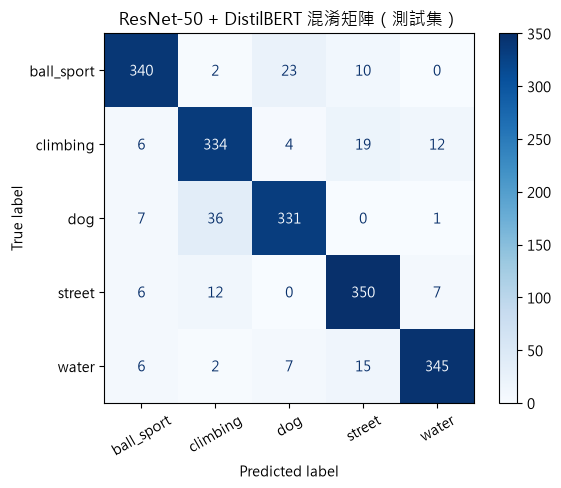

In [12]:
base = train_fusion("resnet50", "distilbert", "fusion")
print(f"基準組合 ResNet-50 + DistilBERT → 測試 Accuracy {base['acc']:.4f} | Macro-F1 {base['macro_f1']:.4f} | 訓練 {base['train_time']:.1f}s")
ConfusionMatrixDisplay(confusion_matrix(base["y_te"], base["pred"]), display_labels=MM_CLASSES).plot(cmap="Blues", xticks_rotation=30)
plt.title("ResNet-50 + DistilBERT 混淆矩陣（測試集）"); plt.show()

## 2.5 更換 Backbone：完整 2 × 2 組合 + 消融（fusion / image-only / text-only）

In [13]:
RUNS = {}
for img_name in ["resnet50", "vit_b_16"]:
    for txt_name in ["distilbert", "minilm"]:
        for mode in ["fusion", "image_only", "text_only"]:
            if (img_name, txt_name, mode) == ("resnet50", "distilbert", "fusion"):
                RUNS[(img_name, txt_name, mode)] = base; continue
            RUNS[(img_name, txt_name, mode)] = train_fusion(img_name, txt_name, mode)

mm_table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("model", "pred", "y_te")} for r in RUNS.values()])
mm_table.to_csv(OUT_DIR / "quiz2_multimodal_results.csv", index=False, encoding="utf-8-sig")
display(mm_table.round(4))

,img,txt,mode,val_acc,acc,macro_f1,params_M,train_time,infer_time
0,resnet50,distilbert,fusion,0.9040,0.9067,0.9068,1.9702,1.8890,0.001
1,resnet50,distilbert,image_only,0.8853,0.8720,0.8716,1.7080,1.2689,0.001
2,resnet50,distilbert,text_only,0.9024,0.8949,0.8951,1.7080,1.1292,0.001
3,resnet50,minilm,fusion,0.9104,0.8971,0.8976,1.7736,1.5670,0.002
4,resnet50,minilm,image_only,0.8827,0.8667,0.8662,1.5114,1.2027,0.001
5,resnet50,minilm,text_only,0.9120,0.9141,0.9141,1.5114,1.1213,0.001
6,vit_b_16,distilbert,fusion,0.9152,0.9147,0.9149,1.3148,1.3745,0.001
7,vit_b_16,distilbert,image_only,0.8800,0.8667,0.8665,1.0527,1.1512,0.000
8,vit_b_16,distilbert,text_only,0.9051,0.8859,0.8861,1.0527,1.1029,0.001
9,vit_b_16,minilm,fusion,0.9291,0.9168,0.9169,1.1182,1.3309,0.001


## 2.6 比較不同 Backbone 組合

,組合,val_acc,acc,macro_f1,params_M,train_time,infer_time
9,vit_b_16 + minilm,0.9291,0.9168,0.9169,1.1182,1.3309,0.001
6,vit_b_16 + distilbert,0.9152,0.9147,0.9149,1.3148,1.3745,0.001
0,resnet50 + distilbert,0.9040,0.9067,0.9068,1.9702,1.8890,0.001
3,resnet50 + minilm,0.9104,0.8971,0.8976,1.7736,1.5670,0.002



--- 消融：各模態單獨 vs 融合（測試 Macro-F1）---


mode                 fusion  image_only  text_only
img      txt                                      
resnet50 distilbert  0.9068      0.8716     0.8951
         minilm      0.8976      0.8662     0.9141
vit_b_16 distilbert  0.9149      0.8665     0.8861
         minilm      0.9169      0.8583     0.9054

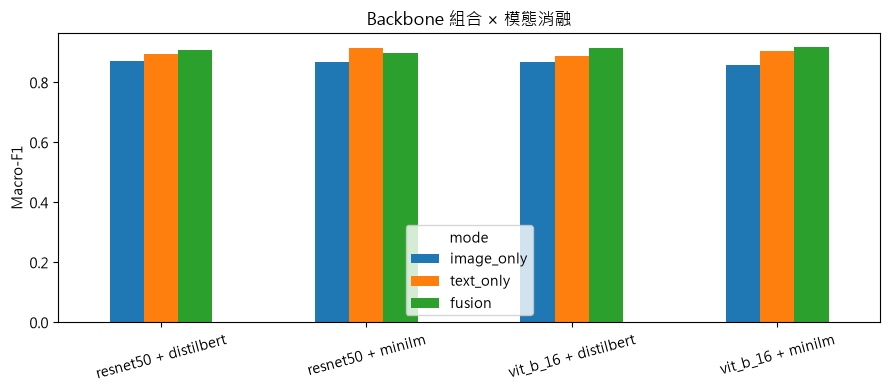

In [14]:
fus = mm_table[mm_table["mode"] == "fusion"].copy()
fus["組合"] = fus.img + " + " + fus.txt
display(fus[["組合", "val_acc", "acc", "macro_f1", "params_M", "train_time", "infer_time"]].round(4).sort_values("macro_f1", ascending=False))

print("\n--- 消融：各模態單獨 vs 融合（測試 Macro-F1）---")
display(mm_table.pivot_table(index=["img", "txt"], columns="mode", values="macro_f1").round(4))

fig, ax = plt.subplots(figsize=(9, 4))
piv = mm_table.pivot_table(index=mm_table.img + " + " + mm_table.txt, columns="mode", values="macro_f1")[["image_only", "text_only", "fusion"]]
piv.plot.bar(ax=ax); ax.set_ylabel("Macro-F1"); ax.set_title("Backbone 組合 × 模態消融"); plt.xticks(rotation=15)
plt.tight_layout(); plt.savefig(OUT_DIR / "quiz2_compare.png", dpi=150); plt.show()

## 2.7 多模態分類推論展示（以驗證集挑出最佳融合組合）

最佳融合組合（依驗證集 Accuracy）: ('vit_b_16', 'minilm') 測試 Accuracy 0.9168


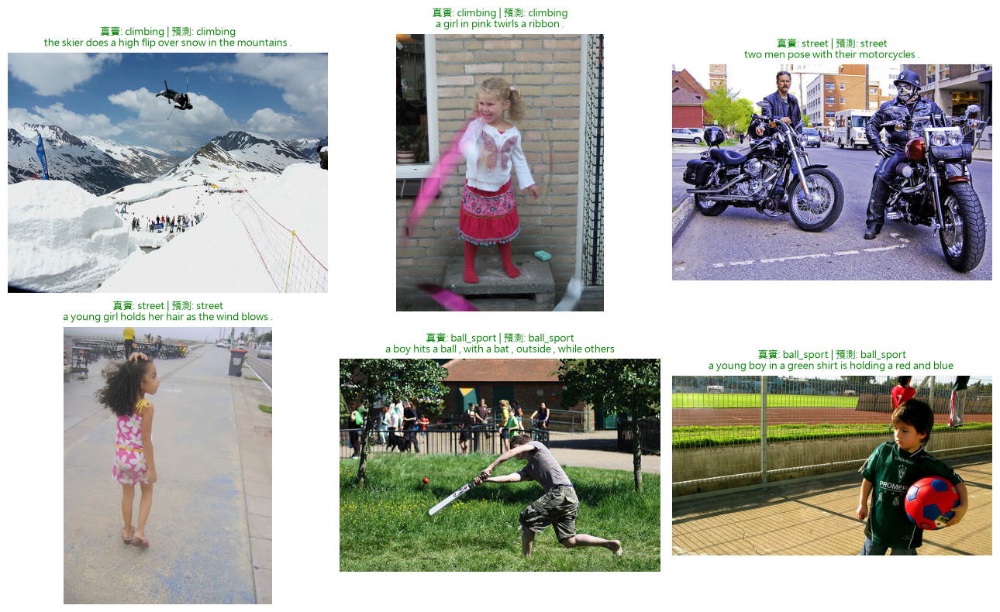

In [15]:
best_key = max([k for k in RUNS if k[2] == "fusion"], key=lambda k: RUNS[k]["val_acc"])
best = RUNS[best_key]; print("最佳融合組合（依驗證集 Accuracy）:", best_key[:2], f"測試 Accuracy {best['acc']:.4f}")

te_pairs = te_idx.numpy(); pred_map = dict(zip(te_pairs, best["pred"]))
pick = np.random.RandomState(1).choice(te_pairs, 6, replace=False)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, p in zip(axes.ravel(), pick):
    r = mm.iloc[int(p) // 5]; pr = MM_CLASSES[pred_map[p]]
    ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
    ax.set_title(f"真實: {r.label} | 預測: {pr}\n" + MM_TEXTS[p][:55], fontsize=9, color="green" if pr == r.label else "red")
plt.tight_layout(); plt.show()

### Quiz 2 結果分析

- **模型比較：** ViT-B/16 + MiniLM 的表現最佳，測試 Accuracy 為 0.9168、Macro-F1 為 0.9169。
- **模態比較：** 多數情況下融合模型優於單一模態，但 ResNet-50 + MiniLM 的 text-only 表現反而較好，顯示融合不一定帶來提升。
- **結果限制：** 標籤由描述文字的關鍵字規則產生，因此文字模型可能直接利用標籤線索；結果應謹慎解讀，後續可使用人工標註及多個隨機種子驗證。

---
# Quiz 3：CLIP Image Captioning

**架構（ClipCap 風格）：** `CLIP ViT-B/32 Image Encoder` → 影像 embedding (512 維) → **MLP Mapper** → 10 個 prefix token → **DistilGPT-2 文字 Decoder** 自回歸產生描述。

- CLIP Image Encoder 凍結並預先萃取特徵；訓練 Mapper 與 GPT-2 Decoder。
- 資料：沿用 Week 4 的 **Flickr8k**（每張影像 5 句描述），切分為 6,000 / 1,000 / 其餘影像（訓練 / 驗證 / 測試）。
- 評估：BLEU-1、BLEU-4、BERTScore-F1，並與 Week 4 結果比較。

## 3.1 資料準備（Flickr8k）

In [16]:
from transformers import CLIPModel, GPT2LMHeadModel, GPT2TokenizerFast

all_imgs = sorted(cap_df.image.unique())
random.Random(SEED).shuffle(all_imgs)
if QUICK: all_imgs = all_imgs[:600]
n_tr, n_va = (400, 100) if QUICK else (6000, 1000)
cap_tr_imgs, cap_va_imgs, cap_te_imgs = all_imgs[:n_tr], all_imgs[n_tr:n_tr + n_va], all_imgs[n_tr + n_va:]
cap_grp = cap_df.groupby("image").caption.apply(lambda s: list(s)[:5])
print(f"影像數：訓練 {len(cap_tr_imgs)} / 驗證 {len(cap_va_imgs)} / 測試 {len(cap_te_imgs)}")
print("範例描述:", cap_grp[cap_tr_imgs[0]][:2])

影像數：訓練 6000 / 驗證 1000 / 測試 1091
範例描述: ['a black and white dog is playing with a sheep in a field .', 'a dog and sheep run together .']


## 3.2 CLIP Image Encoder 特徵萃取（凍結，快取到 `data/`）

In [17]:
CLIP_NAME = "openai/clip-vit-base-patch32"
clip_tf = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC), transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711))])

@torch.no_grad()
def extract_clip_feats(img_names, bs=64):
    clip = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval(); out = []
    paths = [str(IMG_DIR / n) for n in img_names]
    for x in tqdm(DataLoader(PathDS(paths, clip_tf), batch_size=bs, num_workers=NUM_WORKERS), desc="CLIP image encoder"):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            vision_outputs = clip.vision_model(pixel_values=x.to(DEVICE))
            image_features = clip.visual_projection(vision_outputs.pooler_output)
            out.append(image_features.float().cpu())
    del clip; torch.cuda.empty_cache()
    return torch.cat(out)

ALL_NAMES = cap_tr_imgs + cap_va_imgs + cap_te_imgs
CLIP_F = cached(DATA_DIR / f"clip_feats_{tag}.pt", lambda: extract_clip_feats(ALL_NAMES))
name2row = {n: i for i, n in enumerate(ALL_NAMES)}
print("CLIP 影像特徵:", tuple(CLIP_F.shape))

CLIP 影像特徵: (8091, 512)


## 3.3 建立 CLIP + GPT-2 Captioning 模型

In [18]:
tok = GPT2TokenizerFast.from_pretrained("distilgpt2")
tok.pad_token = tok.eos_token
MAX_LEN = 40

def encode_caption(c):
    return tok(c, truncation=True, max_length=MAX_LEN - 1)["input_ids"] + [tok.eos_token_id]

class CapDS(Dataset):
    def __init__(self, img_names):
        self.items = [(name2row[n], encode_caption(c)) for n in img_names for c in cap_grp[n]]
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return self.items[i]

def collate(batch):
    L = max(len(ids) for _, ids in batch)
    ids = torch.full((len(batch), L), tok.eos_token_id); mask = torch.zeros(len(batch), L, dtype=torch.long)
    for i, (_, x) in enumerate(batch): ids[i, :len(x)] = torch.tensor(x); mask[i, :len(x)] = 1
    return CLIP_F[[r for r, _ in batch]], ids, mask

class ClipCaptioner(nn.Module):
    def __init__(self, clip_dim=512, prefix_len=10, gpt_name="distilgpt2"):
        super().__init__()
        self.gpt = GPT2LMHeadModel.from_pretrained(gpt_name)
        self.P, d = prefix_len, self.gpt.config.n_embd
        self.mapper = nn.Sequential(nn.LayerNorm(clip_dim), nn.Linear(clip_dim, d * prefix_len // 2), nn.Tanh(),
                                    nn.Linear(d * prefix_len // 2, d * prefix_len))
    def prefix(self, clip_feat):
        return self.mapper(clip_feat).view(clip_feat.shape[0], self.P, -1)
    def forward(self, clip_feat, ids, mask):
        x = torch.cat([self.prefix(clip_feat), self.gpt.transformer.wte(ids)], dim=1)
        m = torch.cat([torch.ones(ids.shape[0], self.P, dtype=mask.dtype, device=mask.device), mask], dim=1)
        logits = self.gpt(inputs_embeds=x, attention_mask=m).logits
        return logits[:, self.P - 1:-1]          # 位置 P-1 預測第 0 個 token

cap_model = ClipCaptioner().to(DEVICE)
print(f"Captioning 模型參數量：{count_params(cap_model):.2f} M（含 Mapper {count_params(cap_model.mapper):.2f} M；CLIP Encoder 另計且凍結）")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Captioning 模型參數量：113.38 M（含 Mapper 31.47 M；CLIP Encoder 另計且凍結）


## 3.4 訓練 Captioning 模型

caption ep1/8:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 1: train loss 2.6872 | val loss 2.3494


caption ep2/8:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 2: train loss 2.2536 | val loss 2.2713


caption ep3/8:   0%|          | 0/469 [00:00<?, ?it/s]

...

epoch 6: train loss 1.7167 | val loss 2.2852


caption ep7/8:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 7: train loss 1.6152 | val loss 2.3236


caption ep8/8:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 8: train loss 1.5254 | val loss 2.3633
訓練時間 609.5s | 最佳 val loss 2.2486


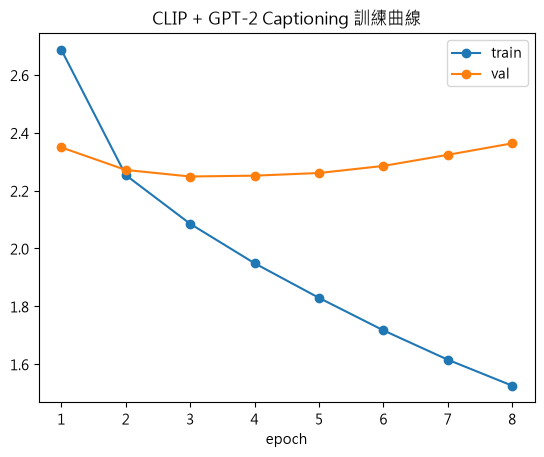

In [19]:
EPOCHS_CAP = 1 if QUICK else 8
BS_CAP = 64
tr_loader = DataLoader(CapDS(cap_tr_imgs), batch_size=BS_CAP, shuffle=True, collate_fn=collate)
va_loader = DataLoader(CapDS(cap_va_imgs), batch_size=128, shuffle=False, collate_fn=collate)

opt = torch.optim.AdamW([
    {"params": cap_model.gpt.parameters(), "lr": 5e-5},
    {"params": cap_model.mapper.parameters(), "lr": 1e-3}], weight_decay=1e-2)
total = EPOCHS_CAP * len(tr_loader)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 200) * max(0.0, 1 - s / total))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

def cap_loss(model, feats, ids, mask):
    feats, ids, mask = feats.to(DEVICE), ids.to(DEVICE), mask.to(DEVICE)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
        logits = model(feats, ids, mask)
    labels = ids.masked_fill(mask == 0, -100)
    return F.cross_entropy(logits.float().reshape(-1, logits.shape[-1]), labels.reshape(-1), ignore_index=-100)

cap_hist, best_val, best_state = [], 1e9, None
sync(); t_start = time.time()
for ep in range(EPOCHS_CAP):
    cap_model.train(); tot, n = 0.0, 0
    for feats, ids, mask in tqdm(tr_loader, desc=f"caption ep{ep+1}/{EPOCHS_CAP}", leave=False):
        loss = cap_loss(cap_model, feats, ids, mask)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(cap_model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    cap_model.eval(); vt, vn = 0.0, 0
    with torch.no_grad():
        for feats, ids, mask in va_loader: vt += cap_loss(cap_model, feats, ids, mask).item(); vn += 1
    cap_hist.append({"epoch": ep + 1, "train_loss": tot / n, "val_loss": vt / vn})
    print(f"epoch {ep+1}: train loss {tot/n:.4f} | val loss {vt/vn:.4f}")
    if vt / vn < best_val: best_val, best_state = vt / vn, copy.deepcopy(cap_model.state_dict())
sync(); cap_train_time = time.time() - t_start
cap_model.load_state_dict(best_state); cap_model.eval()
print(f"訓練時間 {cap_train_time:.1f}s | 最佳 val loss {best_val:.4f}")

hist_df = pd.DataFrame(cap_hist)
plt.plot(hist_df.epoch, hist_df.train_loss, marker="o", label="train"); plt.plot(hist_df.epoch, hist_df.val_loss, marker="o", label="val")
plt.title("CLIP + GPT-2 Captioning 訓練曲線"); plt.xlabel("epoch"); plt.legend(); plt.show()

## 3.5 產生影像描述（Greedy / Beam Search）

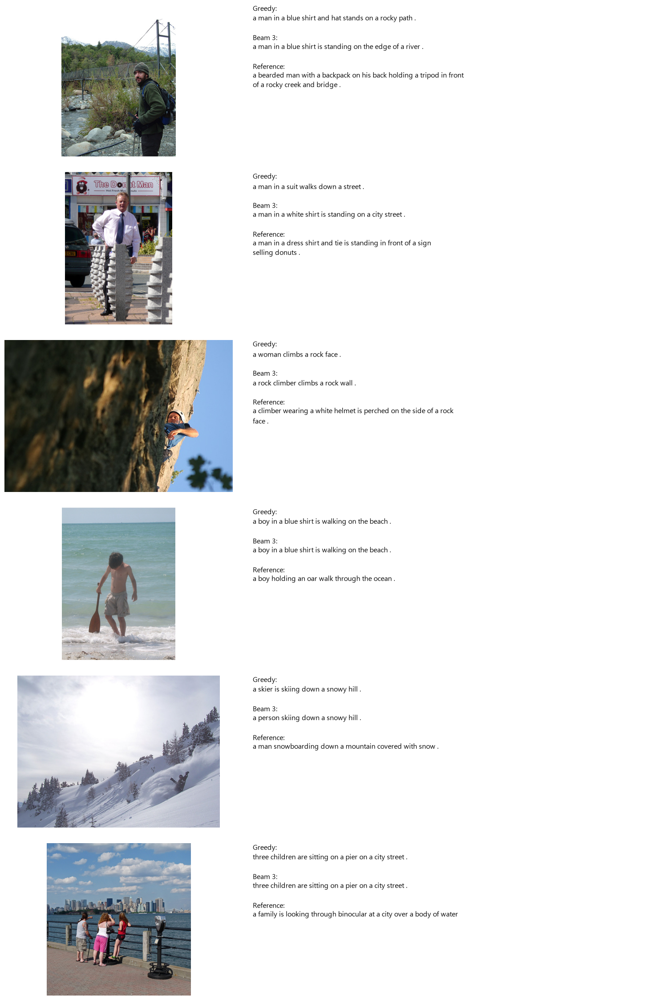

In [20]:
@torch.no_grad()
def generate_captions(model, feats, num_beams=1, bs=100, max_new_tokens=30):
    model.eval(); outs = []
    kw = dict(early_stopping=True) if num_beams > 1 else {}
    for i in range(0, len(feats), bs):
        pre = model.prefix(feats[i:i + bs].to(DEVICE))
        am = torch.ones(pre.shape[:2], dtype=torch.long, device=DEVICE)
        ids = model.gpt.generate(inputs_embeds=pre, attention_mask=am, max_new_tokens=max_new_tokens,
                                 num_beams=num_beams, do_sample=False, no_repeat_ngram_size=3,
                                 pad_token_id=tok.eos_token_id, eos_token_id=tok.eos_token_id, **kw)
        outs += [s.strip() for s in tok.batch_decode(ids, skip_special_tokens=True)]
    return outs

def measure_latency(model, feats, num_beams, n=100):
    """bs=1 逐張產生，量測每張平均回覆時間（秒）"""
    f = feats[:n]; generate_captions(model, f[:2], num_beams, bs=1)       # warm-up
    sync(); t0 = time.time(); generate_captions(model, f, num_beams, bs=1); sync()
    return (time.time() - t0) / len(f)

te_feats = CLIP_F[[name2row[n] for n in cap_te_imgs]]
te_refs = [cap_grp[n] for n in cap_te_imgs]
caps_greedy = generate_captions(cap_model, te_feats, num_beams=1)
caps_beam = generate_captions(cap_model, te_feats, num_beams=3)

import textwrap
sample_ids = np.random.RandomState(3).choice(len(cap_te_imgs), 6, replace=False)
fig, axes = plt.subplots(
    len(sample_ids), 2, figsize=(16, 3.8 * len(sample_ids)),
    gridspec_kw={"width_ratios": [1, 1.5]}, squeeze=False,
)
for row, i in enumerate(sample_ids):
    img_ax, text_ax = axes[row]
    img_ax.imshow(Image.open(IMG_DIR / cap_te_imgs[i]).convert("RGB"))
    img_ax.axis("off")

    lines = [
        ("Greedy", caps_greedy[i]),
        ("Beam 3", caps_beam[i]),
        ("Reference", te_refs[i][0]),
    ]
    caption_text = "\n\n".join(
        f"{label}:\n{textwrap.fill(text, width=68)}"
        for label, text in lines
    )
    text_ax.text(0, 1, caption_text, va="top", fontsize=11, linespacing=1.4)
    text_ax.axis("off")

fig.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.0)
plt.show()

## 3.6 評估：BLEU-1 / BLEU-4 / BERTScore-F1

In [21]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from bert_score import score as bert_score_fn

def toks(s): return re.findall(r"[a-z0-9']+", s.lower())

def eval_captions(cands, refs_list):
    hyp = [toks(c) for c in cands]; refs = [[toks(r) for r in rs] for rs in refs_list]
    sm = SmoothingFunction().method1
    b1 = corpus_bleu(refs, hyp, weights=(1, 0, 0, 0), smoothing_function=sm)
    b4 = corpus_bleu(refs, hyp, weights=(0.25,) * 4, smoothing_function=sm)
    _, _, f1 = bert_score_fn(cands, refs_list, lang="en", batch_size=64, device=DEVICE)
    return {"BLEU-1": b1, "BLEU-4": b4, "BERTScore-F1": f1.mean().item()}

N_SMALL = 20 if QUICK else 100       # Week 4 以 N=100 張評估，這裡同樣報告 N=100 以便對照
lat_g = measure_latency(cap_model, te_feats, 1, N_SMALL)
lat_b = measure_latency(cap_model, te_feats, 3, N_SMALL)

new_rows = []
for name, caps, lat in [("CLIP+GPT2-Greedy", caps_greedy, lat_g), ("CLIP+GPT2-Beam (k=3)", caps_beam, lat_b)]:
    new_rows.append({"方法": name, "評估張數 (N)": N_SMALL, "回覆時間 (s/張)": lat, **eval_captions(caps[:N_SMALL], te_refs[:N_SMALL]), "參數量 (M)": count_params(cap_model)})
    new_rows.append({"方法": name + " [全測試集]", "評估張數 (N)": len(cap_te_imgs), "回覆時間 (s/張)": np.nan, **eval_captions(caps, te_refs), "參數量 (M)": count_params(cap_model)})
new_df = pd.DataFrame(new_rows); display(new_df.round(4))

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,方法,評估張數 (N),回覆時間 (s/張),BLEU-1,BLEU-4,BERTScore-F1,參數量 (M)
0,CLIP+GPT2-Greedy,100,0.0407,0.6571,0.2504,0.9398,113.3824
1,CLIP+GPT2-Greedy [全測試集],1091,NaN,0.6522,0.2328,0.9376,113.3824
2,CLIP+GPT2-Beam (k=3),100,0.0518,0.6484,0.2446,0.9399,113.3824
3,CLIP+GPT2-Beam (k=3) [全測試集],1091,NaN,0.6752,0.2466,0.9391,113.3824


## 3.7 與 Week 4 比較

Week 4 的數據取自 Week 4 README 的實驗結果（N=100）。

> **公平性提醒：** Week 4 與本次的測試圖片切分不一定相同；表中 N=100 的列是「本次測試集前 100 張」，僅供對照。若要嚴格比較，請在同一份切分上重新評估 Week 4 的模型（LSTM / BLIP）。

,方法,評估張數 (N),回覆時間 (s/張),BLEU-1,BLEU-4,BERTScore-F1,參數量 (M)
0,Week4 LSTM-Greedy,100,0.0062,0.5651,0.1809,0.8310,4.9894
1,Week4 LSTM-Beam (k=3),100,0.0176,0.5275,0.1518,0.8359,4.9894
2,Week4 BLIP-pretrained,100,0.1777,0.5850,0.2427,0.8488,NaN
3,CLIP+GPT2-Greedy,100,0.0407,0.6571,0.2504,0.9398,113.3824
4,CLIP+GPT2-Beam (k=3),100,0.0518,0.6484,0.2446,0.9399,113.3824


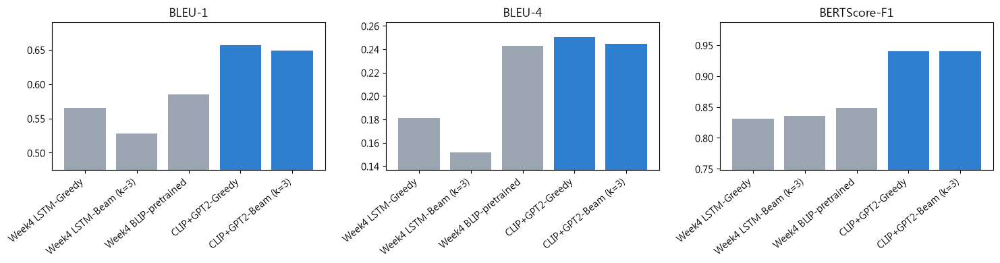

BLEU-1 最高：CLIP+GPT2-Greedy (0.6571)
BLEU-4 最高：CLIP+GPT2-Greedy (0.2504)
BERTScore-F1 最高：CLIP+GPT2-Beam (k=3) (0.9399)


In [22]:
week4 = pd.DataFrame([
    {"方法": "Week4 LSTM-Greedy",   "評估張數 (N)": 100, "回覆時間 (s/張)": 0.0062, "BLEU-1": 0.5651, "BLEU-4": 0.1809, "BERTScore-F1": 0.8310, "參數量 (M)": 4.9894},
    {"方法": "Week4 LSTM-Beam (k=3)", "評估張數 (N)": 100, "回覆時間 (s/張)": 0.0176, "BLEU-1": 0.5275, "BLEU-4": 0.1518, "BERTScore-F1": 0.8359, "參數量 (M)": 4.9894},
    {"方法": "Week4 BLIP-pretrained", "評估張數 (N)": 100, "回覆時間 (s/張)": 0.1777, "BLEU-1": 0.5850, "BLEU-4": 0.2427, "BERTScore-F1": 0.8488, "參數量 (M)": np.nan},
])
compare = pd.concat([week4, new_df[new_df["評估張數 (N)"] == N_SMALL]], ignore_index=True)
compare.to_csv(OUT_DIR / "quiz3_caption_compare.csv", index=False, encoding="utf-8-sig")
new_df.to_csv(OUT_DIR / "quiz3_caption_results_full.csv", index=False, encoding="utf-8-sig")
display(compare.round(4))

metrics = ["BLEU-1", "BLEU-4", "BERTScore-F1"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, metrics):
    ax.bar(compare["方法"], compare[m], color=["#9aa5b1"] * 3 + ["#2f7fd1"] * (len(compare) - 3))
    ax.set_title(m); ax.tick_params(axis="x", rotation=40)
    for lbl in ax.get_xticklabels(): lbl.set_ha("right")
    ax.set_ylim(compare[m].min() * 0.9, compare[m].max() * 1.05)
plt.tight_layout(); plt.savefig(OUT_DIR / "quiz3_compare.png", dpi=150); plt.show()

# 自動摘要（以實際數字為準）
for m in metrics:
    top = compare.loc[compare[m].idxmax()]
    print(f"{m} 最高：{top['方法']} ({top[m]:.4f})")

### Quiz 3 結果分析

- **BLEU / BERTScore：** 比較 CLIP+GPT-2 與 Week 4 LSTM（Greedy / Beam）、BLIP 的差異；BLEU 看 n-gram 重疊，BERTScore 看語意相似度，兩者排名可能不同。
- **為什麼 CLIP 可能有幫助：** CLIP 影像特徵經過大規模影像-文字對比預訓練，與語言空間較接近；GPT-2 Decoder 也帶有預訓練語言知識，相較於從零訓練的 LSTM 更容易產生流暢、語意正確的句子。
- **Greedy vs Beam：** 比較兩種解碼在各指標與回覆時間上的差異。
- **成本：** 參數量（DistilGPT-2 約 82M，遠大於 Week 4 LSTM 約 5M）與回覆時間。
- **限制：** 測試切分與 Week 4 可能不同、單一隨機種子、BLEU 對同義改寫不敏感。

---
# 綜合結論（請依實際結果微調）

1. **影像檢索（Quiz 1）：** 比較 CNN 與 ViT 的 Recall@K / mAP 與計算成本，說明在資源與品質之間的取捨。
2. **多模態分類（Quiz 2）：** 比較 4 種 Backbone 組合，並以消融實驗說明影像、文字與融合各自的貢獻（注意標籤洩漏的限制）。
3. **CLIP Image Captioning（Quiz 3）：** 比較 Week 4 與 CLIP + GPT-2 的 BLEU / BERTScore，說明預訓練視覺-語言表示的影響。

所有結果表格與圖已輸出到 `outputs/`。